In [1]:
import os
import scanpy as sc
import pandas as pd
from scipy import sparse
import anndata as ad
import sys
import hdf5plugin
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
import parameters
import genes
import functions
from scipy.sparse import csr_matrix
import warnings
warnings.filterwarnings("ignore")

In [2]:
parameters.pc_parameters

{'n_pcs': 30, 'n_neighbors': 20, 'leiden_resolution': 0.5}

## de Faria data

In [3]:
path = "/home/sofia/Projects/etmr/defaria/scRNA/data/raw"
defaria = sc.read_10x_mtx(path)

In [4]:
defaria

AnnData object with n_obs × n_vars = 2883 × 33694
    var: 'gene_ids', 'feature_types'

In [5]:
defaria.layers["counts"] = defaria.X.copy()

In [6]:
defaria = functions.filter_anndata(defaria, "/home/sofia/Projects/etmr/defaria/scRNA/data/raw/plot/plot")
defaria = functions.preprocess_adata(defaria)

In [7]:
defaria

AnnData object with n_obs × n_vars = 2035 × 33694
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'filters', 'hvg', 'log1p'
    layers: 'counts', 'scale.data'

### Dimensionality reduction

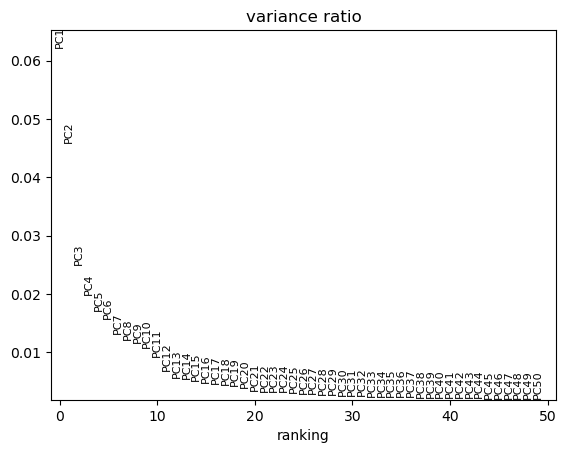

In [8]:
sc.pp.pca(defaria, use_highly_variable=True,  n_comps=50, layer="scale.data") #compute PCA using the scaled data in the "scale.data" layer, and only using the highly variable genes identified earlier

sc.pl.pca_variance_ratio(defaria, n_pcs=50, log=False, show=False) #plot the variance explained by each of the first 50 PCs, to help determine how many PCs to use for downstream analyses


In [9]:
pc_parameters = parameters.pc_parameters

sc.pp.neighbors(
                defaria,
                n_neighbors=pc_parameters["n_neighbors"],
                n_pcs=pc_parameters["n_pcs"]
            ) #compute the neighborhood graph of cells using the specified number of neighbors and PCs, which will be used for UMAP and Leiden clustering

            # UMAP
sc.tl.umap(
                defaria
            )

            # Leiden
sc.tl.leiden(
                defaria,
                resolution=pc_parameters["leiden_resolution"]
            )

In [10]:
defaria.uns["leiden"]

{'params': {'resolution': 0.5, 'random_state': 0, 'n_iterations': -1}}

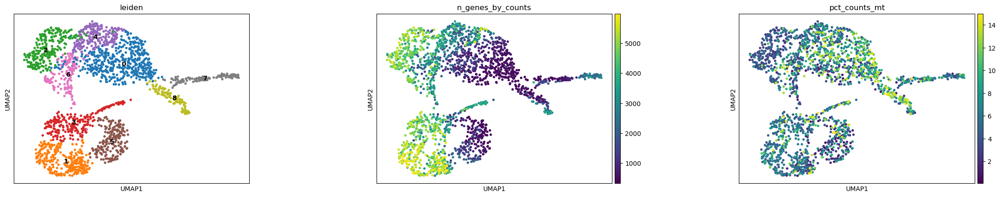

In [11]:
sc.pl.umap(defaria, color=["leiden", "n_genes_by_counts", "pct_counts_mt"], wspace=0.4, legend_loc='on data')

### Cell cycle

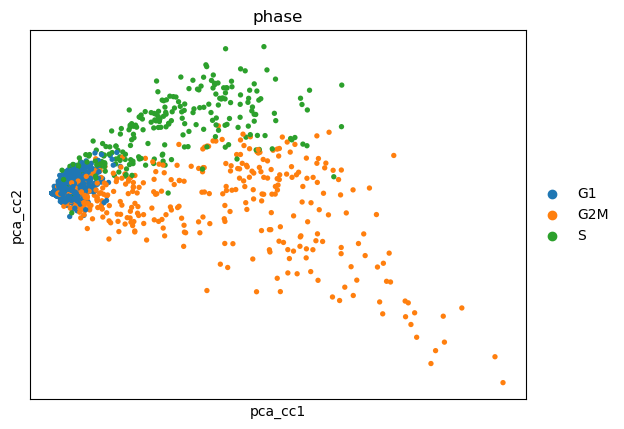

In [12]:
s_genes = [x for x in genes.s_genes if x in defaria.var_names]

g2m_genes = [x for x in genes.g2m_genes if x in defaria.var_names]

cell_cycle_genes = [*s_genes, *g2m_genes]

sc.tl.score_genes_cell_cycle(defaria, s_genes=s_genes, g2m_genes=g2m_genes)

datacc_genes = defaria[:, cell_cycle_genes].copy()
sc.tl.pca(datacc_genes, layer="scale.data", key_added="pca_cc")
sc.pl.embedding(datacc_genes, color="phase", basis="pca_cc")

sc.tl.rank_genes_groups(defaria, groupby="leiden",  method="wilcoxon", use_raw=False)

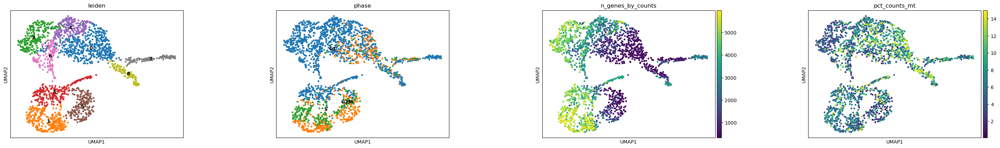

In [13]:
sc.pl.umap(defaria, color=["leiden", "phase", "n_genes_by_counts", "pct_counts_mt"], wspace=0.4, legend_loc='on data')

In [14]:
defaria

AnnData object with n_obs × n_vars = 2035 × 33694
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'leiden', 'S_score', 'G2M_score', 'phase'
    var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'filters', 'hvg', 'log1p', 'pca', 'neighbors', 'umap', 'leiden', 'leiden_colors', 'rank_genes_groups', 'phase_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts', 'scale.data'
    obsp: 'distances', 'connectivities'

### Cluster id

categories: 0, 1, 2, etc.
var_group_labels: Endothelial, Red blood cells, VLMC, etc.


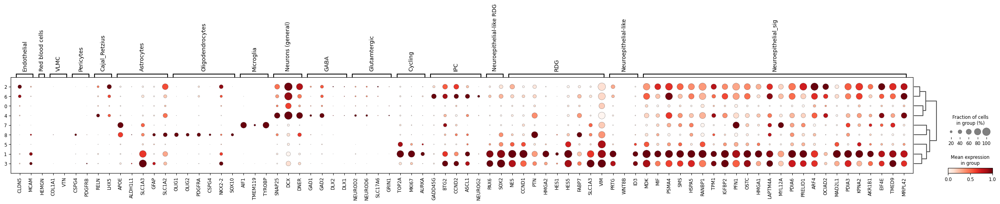

categories: 0, 1, 2, etc.
var_group_labels: Astrocytes, Microglia, IPC, etc.


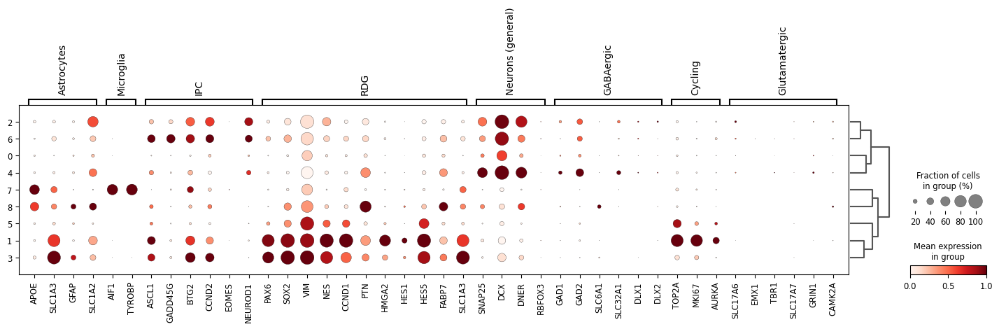

In [15]:
sc.tl.dendrogram(defaria, groupby="leiden")

# for name, gene in genes.prov_ann.items(): 
#     sc.pl.dotplot(defaria, var_names=gene, groupby="leiden", standard_scale=None, dendrogram=True, title=name)
    
sc.pl.dotplot(defaria, var_names=genes.prov_ann, groupby="leiden",standard_scale="var", dendrogram=True)
sc.pl.dotplot(defaria, var_names=genes.etmr1_markers, groupby="leiden",standard_scale="var", dendrogram=True)

categories: 0, 1, 2, etc.
var_group_labels: Endothelial, Red blood cells, VLMC, etc.


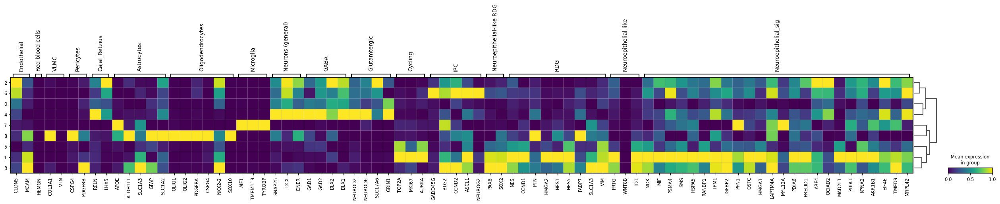

categories: 0, 1, 2, etc.
var_group_labels: Astrocytes, Microglia, IPC, etc.


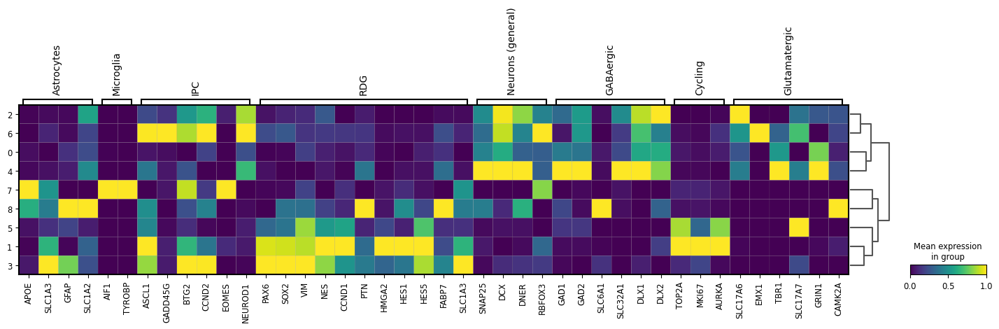

In [16]:
# for name, gene in genes.prov_ann.items(): 
#     sc.pl.matrixplot(defaria, gene, groupby="leiden", dendrogram=True, title=name)

sc.pl.matrixplot(defaria, genes.prov_ann, groupby="leiden", dendrogram=True, standard_scale="var")
sc.pl.matrixplot(defaria, genes.etmr1_markers, groupby="leiden", dendrogram=True, standard_scale="var")

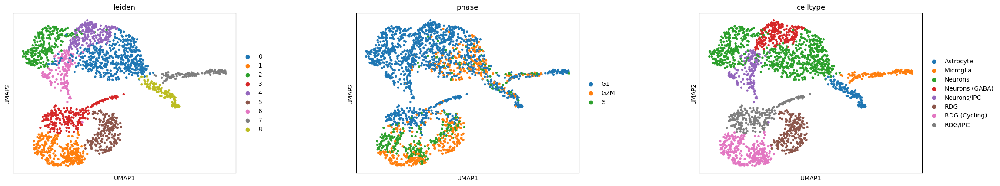

In [17]:
cluster_id = {
    "0":"Neurons",
    "1":"RDG (Cycling)",
    "2": "Neurons",
    "3": "RDG/IPC",
    "4":"Neurons (GABA)",
    "5": "RDG",
    "6": "Neurons/IPC",
    "7": "Microglia",
    "8":"Astrocyte"

}

defaria.obs["celltype"] = (
    defaria.obs["leiden"]
    .map(cluster_id)
)

sc.pl.embedding(defaria, basis="umap", color=["leiden", "phase", "celltype"], wspace=0.4)

In [18]:
genes.prov_ann.items()

dict_items([('Endothelial', ['CLDN5', 'MCAM']), ('Red blood cells', ['HEMGN']), ('VLMC', ['COL1A1', 'VTN']), ('Pericytes', ['CSPG4', 'PDGFRB']), ('Cajal_Retzius', ['RELN', 'LHX5']), ('Astrocytes', ['APOE', 'ALDH1L1', 'SLC1A3', 'GFAP', 'SLC1A2']), ('Oligodendrocytes', ['OLIG1', 'OLIG2', 'PDGFRA', 'CSPG4', 'NKX2-2', 'SOX10']), ('Microglia', ['AIF1', 'TMEM119', 'TYROBP']), ('Neurons (general)', ['SNAP25', 'DCX', 'DNER']), ('GABA', ['GAD1', 'GAD2', 'DLX2', 'DLX1']), ('Glutamtergic', ['NEUROD2', 'NEUROD6', 'SLC17A6', 'GRIN1']), ('Cycling', ['TOP2A', 'MKI67', 'AURKA']), ('IPC', ['GADD45G', 'BTG2', 'CCND2', 'ASCL1', 'NEUROG2']), ('Neuroepithelial-like RDG', ['PAX6', 'SOX2']), ('RDG', ['NES', 'CCND1', 'PTN', 'HMGA2', 'HES1', 'HES5', 'FABP7', 'SLC1A3', 'VIM']), ('Neuroepithelial-like', ['PRTG', 'WNT8B', 'ID3']), ('Neuroepithelial_sig', ['MDK', 'MIF', 'PSMA4', 'SMS', 'HSPA5', 'RANBP1', 'TPM1', 'IGFBP2', 'PFN1', 'OSTC', 'HMGA1', 'LAPTM4A', 'MYL12A', 'PDIA6', 'PRELID1', 'ARF4', 'OCIAD2', 'MAD2L1',

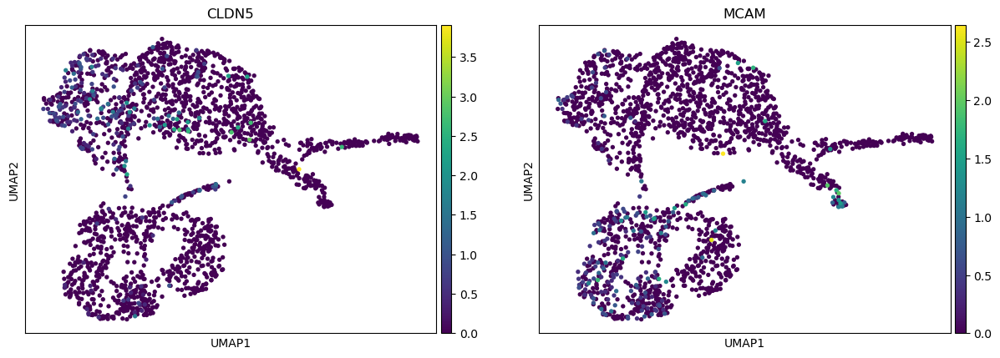

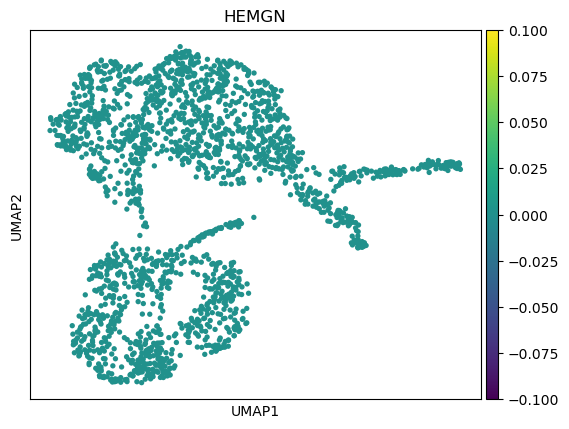

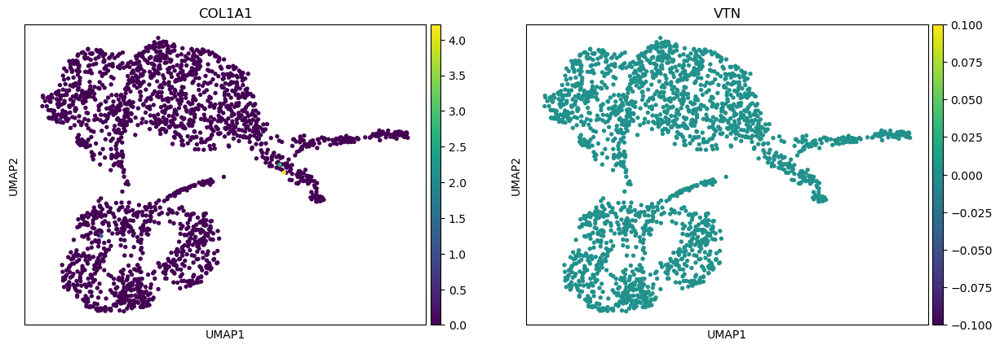

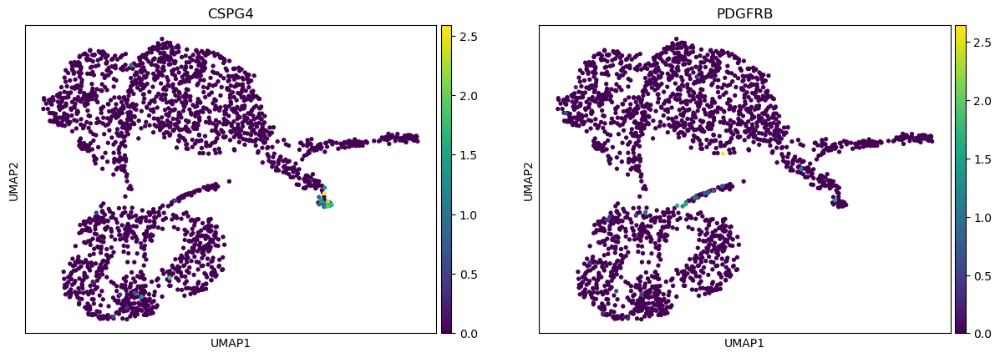

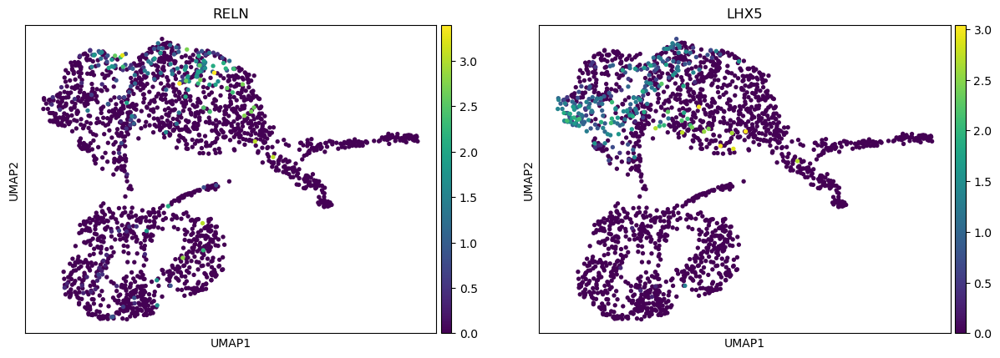

...

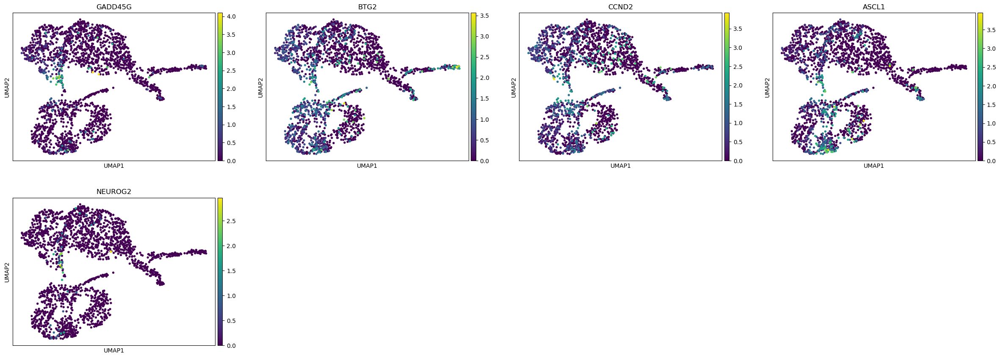

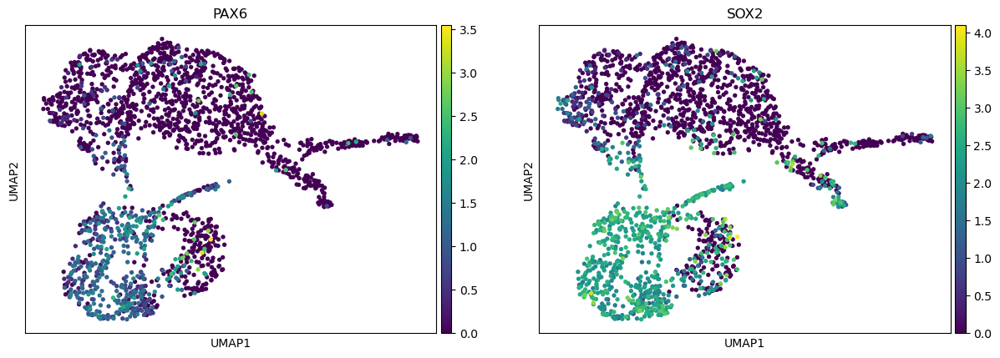

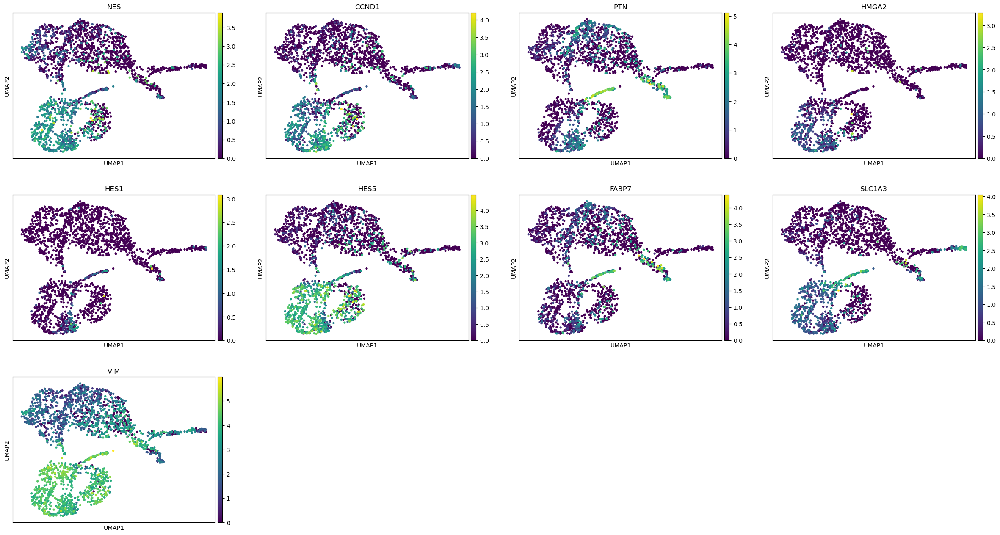

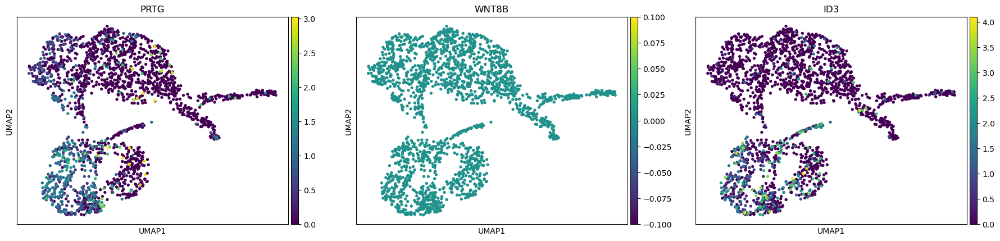

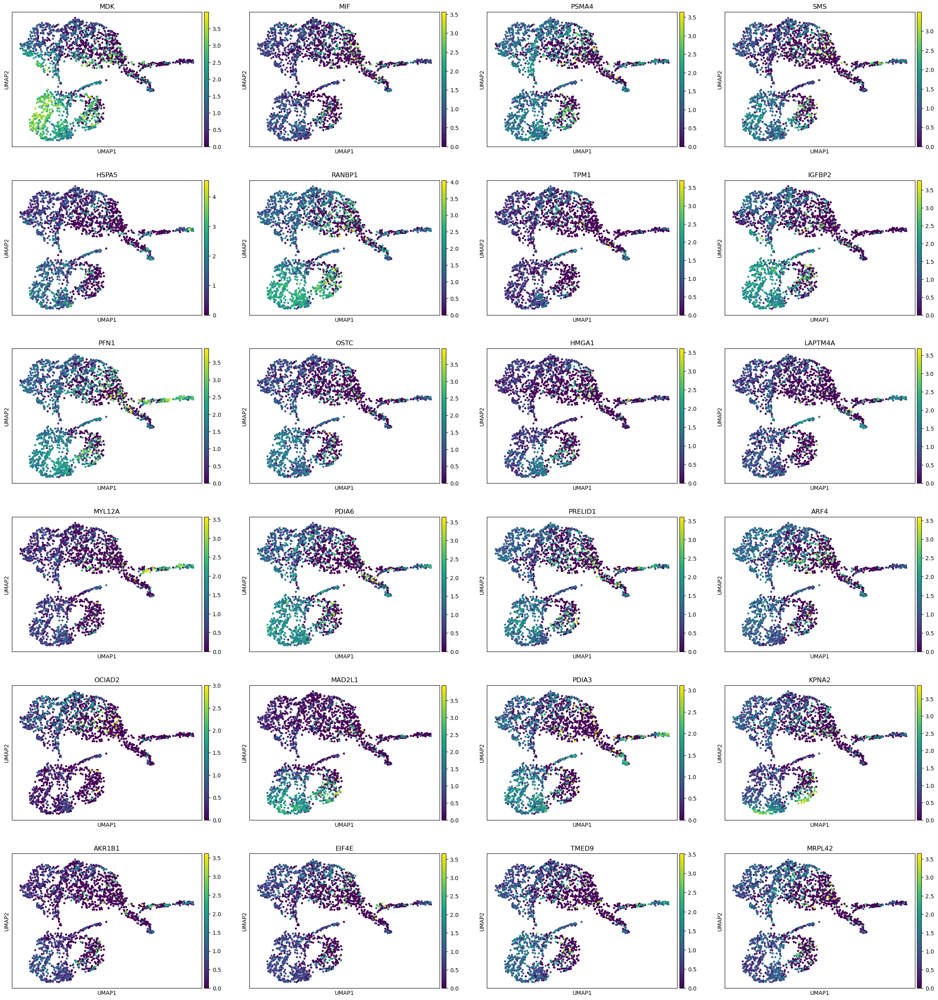

In [19]:
for name, gene in genes.prov_ann.items(): 
    sc.pl.umap(defaria, color=gene)


In [20]:
defaria.obs

,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo,leiden,S_score,G2M_score,phase,celltype
AAACCCAGTAGACGTG-1,3104,9248.0,218.0,2.357266,2343.0,25.335207,6,-0.211686,-0.109580,G1,Neurons/IPC
AAACGAATCCGAGCTG-1,676,1095.0,119.0,10.867580,209.0,19.086758,7,-0.063132,0.010030,G2M,Microglia
AAACGAATCGGTCTGG-1,1882,3840.0,222.0,5.781250,70.0,1.822917,0,-0.240926,-0.190155,G1,Neurons
AAACGCTGTTCCGCGA-1,1206,2751.0,92.0,3.344239,833.0,30.279900,5,0.187162,0.068984,S,RDG
AAACGCTTCGTTCTCG-1,406,532.0,10.0,1.879699,77.0,14.473684,0,-0.053632,0.001655,G2M,Neurons
...,...,...,...,...,...,...,...,...,...,...,...
TTTGATCGTTCGGTAT-1,3032,6506.0,235.0,3.612051,342.0,5.256686,2,-0.171034,-0.111011,G1,Neurons
TTTGGAGAGACAGCTG-1,2976,8643.0,250.0,2.892514,1695.0,19.611246,4,-0.141374,-0.101389,G1,Neurons (GABA)
TTTGGTTAGACGCATG-1,4911,19084.0,360.0,1.886397,2249.0,11.784741,2,-0.278186,-0.202116,G1,Neurons
TTTGTTGCAACCCGCA-1,5783,25778.0,1770.0,6.866320,6442.0,24.990303,3,-0.172999,-0.115779,G1,RDG/IPC


## Jessa

In [21]:
jessa = sc.read_h5ad("/home/sofia/Projects/etmr/defaria/scRNA/jessa/data/processed/jessa_pp.h5ad")

In [22]:
jessa

AnnData object with n_obs × n_vars = 6594 × 33950
    obs: 'sample_origin', 'species', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'names', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'filters', 'hvg', 'log1p'
    layers: 'counts', 'scale.data'

In [23]:
defaria.obs["sample_origin"] = "defaria"
defaria.obs["species"] = "human"
jessa.obs["sample_origin"] = "jessa"
jessa.obs["species"] = "human"

In [24]:
jessa.uns

{'filters': {'max_counts': 6000,
  'max_pct_counts_mt': 15,
  'max_total_counts': 40000,
  'min_counts': 200},
 'hvg': {'flavor': 'seurat_v3'},
 'log1p': {'base': None}}

In [25]:
defaria

AnnData object with n_obs × n_vars = 2035 × 33694
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'leiden', 'S_score', 'G2M_score', 'phase', 'celltype', 'sample_origin', 'species'
    var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'filters', 'hvg', 'log1p', 'pca', 'neighbors', 'umap', 'leiden', 'leiden_colors', 'rank_genes_groups', 'phase_colors', 'dendrogram_leiden', 'celltype_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts', 'scale.data'
    obsp: 'distances', 'connectivities'

In [26]:
defaria.uns

OrderedDict([('filters',
              {'min_counts': 200,
               'max_counts': 6000,
               'max_total_counts': 40000,
               'max_pct_counts_mt': 15}),
             ('hvg', {'flavor': 'seurat_v3'}),
             ('log1p', {'base': None}),
             ('pca',
              {'params': {'zero_center': True,
                'use_highly_variable': True,
                'mask_var': 'highly_variable',
                'layer': 'scale.data'},
               'variance': array([124.29907453,  91.90654991,  49.92602701,  39.64085484,
                       34.29823865,  31.58999999,  26.21118521,  24.40977711,
                       23.27120493,  21.56842512,  18.57368606,  13.79836295,
                       11.3419811 ,  10.79441486,  10.2767484 ,   9.39492884,
                        9.29040811,   8.79440869,   8.5720996 ,   7.75692948,
                        6.89235423,   6.61961377,   6.49775766,   6.38651572,
                        6.1192863 ,   5.81882544,   5.6

### Dimensionality reduction

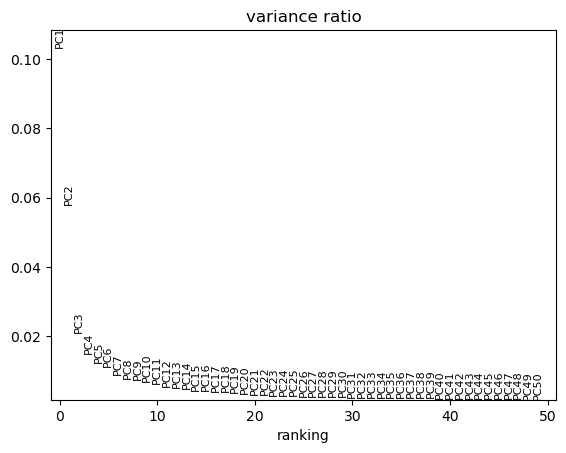

In [27]:
sc.pp.pca(jessa, use_highly_variable=True,  n_comps=50, layer="scale.data") #compute PCA using the scaled data in the "scale.data" layer, and only using the highly variable genes identified earlier

sc.pl.pca_variance_ratio(jessa, n_pcs=50, log=False) #plot the variance explained by each of the first 50 PCs, to help determine how many PCs to use for downstream analyses



sc.pp.neighbors(
                jessa,
                n_neighbors=pc_parameters["n_neighbors"],
                n_pcs=pc_parameters["n_pcs"]
            ) #compute the neighborhood graph of cells using the specified number of neighbors and PCs, which will be used for UMAP and Leiden clustering

            # UMAP
sc.tl.umap(
                jessa
            )

            # Leiden
sc.tl.leiden(
                jessa,
                resolution=pc_parameters["leiden_resolution"]
            )

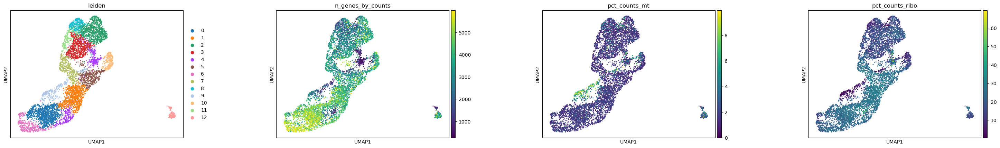

In [28]:
sc.pl.umap(jessa, color=["leiden", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"], wspace=0.4)

### Cell cycle

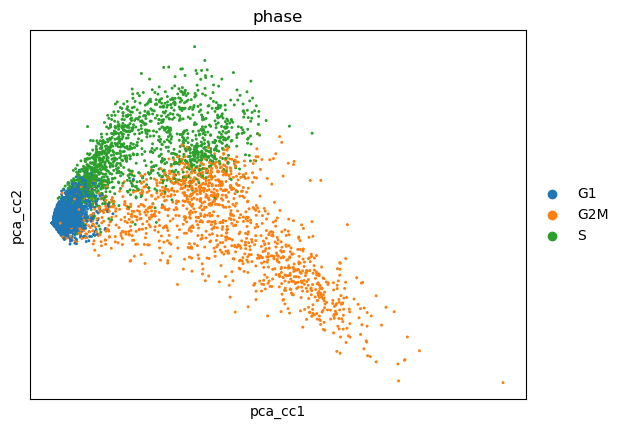

In [29]:
s_genes = [x for x in genes.s_genes if x in jessa.var_names]

g2m_genes = [x for x in genes.g2m_genes if x in jessa.var_names]

cell_cycle_genes = [*s_genes, *g2m_genes]

sc.tl.score_genes_cell_cycle(jessa, s_genes=s_genes, g2m_genes=g2m_genes)

datacc_genes = jessa[:, cell_cycle_genes].copy()
sc.tl.pca(datacc_genes, layer="scale.data", key_added="pca_cc")
sc.pl.embedding(datacc_genes, color="phase", basis="pca_cc")

sc.tl.rank_genes_groups(jessa, groupby="leiden",  method="wilcoxon", use_raw=False)

In [30]:
jessa

AnnData object with n_obs × n_vars = 6594 × 33950
    obs: 'sample_origin', 'species', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'leiden', 'S_score', 'G2M_score', 'phase'
    var: 'names', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'filters', 'hvg', 'log1p', 'pca', 'neighbors', 'umap', 'leiden', 'leiden_colors', 'rank_genes_groups'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts', 'scale.data'
    obsp: 'distances', 'connectivities'

In [31]:
genes.etmr1_markers

{'Astrocytes': ['APOE', 'SLC1A3', 'GFAP', 'SLC1A2'],
 'Microglia': ['AIF1', 'TYROBP'],
 'IPC': ['ASCL1', 'GADD45G', 'BTG2', 'CCND2', 'EOMES', 'NEUROD1'],
 'RDG': ['PAX6',
  'SOX2',
  'VIM',
  'NES',
  'CCND1',
  'PTN',
  'HMGA2',
  'HES1',
  'HES5',
  'FABP7',
  'SLC1A3'],
 'Neurons (general)': ['SNAP25', 'DCX', 'DNER', 'RBFOX3'],
 'GABAergic': ['GAD1', 'GAD2', 'SLC6A1', 'SLC32A1', 'DLX1', 'DLX2'],
 'Cycling': ['TOP2A', 'MKI67', 'AURKA'],
 'Glutamatergic': ['SLC17A6', 'EMX1', 'TBR1', 'SLC17A7', 'GRIN1', 'CAMK2A']}

In [32]:
var_set = set(jessa.var_names)

filtered_markers = {
    celltype: [g for g in gene_list if g in var_set]
    for celltype, gene_list in genes.etmr1_markers.items()
}

In [33]:
filtered_markers

{'Astrocytes': ['APOE', 'SLC1A3', 'GFAP', 'SLC1A2'],
 'Microglia': ['AIF1', 'TYROBP'],
 'IPC': ['ASCL1', 'GADD45G', 'BTG2', 'CCND2', 'NEUROD1'],
 'RDG': ['PAX6',
  'SOX2',
  'VIM',
  'NES',
  'CCND1',
  'PTN',
  'HMGA2',
  'HES1',
  'HES5',
  'FABP7',
  'SLC1A3'],
 'Neurons (general)': ['SNAP25', 'DCX', 'DNER', 'RBFOX3'],
 'GABAergic': ['GAD1', 'GAD2', 'SLC6A1', 'SLC32A1', 'DLX1', 'DLX2'],
 'Cycling': ['TOP2A', 'MKI67', 'AURKA'],
 'Glutamatergic': ['SLC17A6', 'TBR1', 'SLC17A7', 'GRIN1', 'CAMK2A']}

### Cluster id

categories: 0, 1, 2, etc.
var_group_labels: Endothelial, Red blood cells, VLMC, etc.


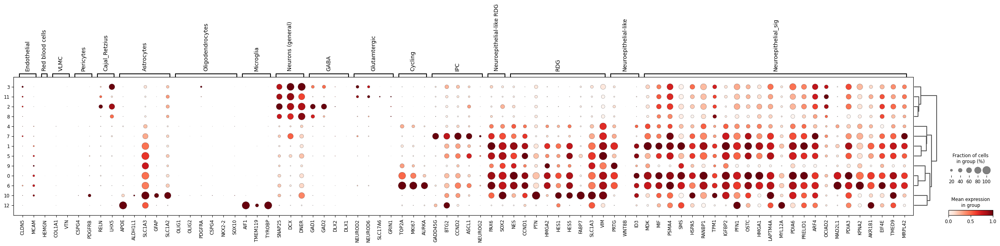

categories: 0, 1, 2, etc.
var_group_labels: Astrocytes, Microglia, IPC, etc.


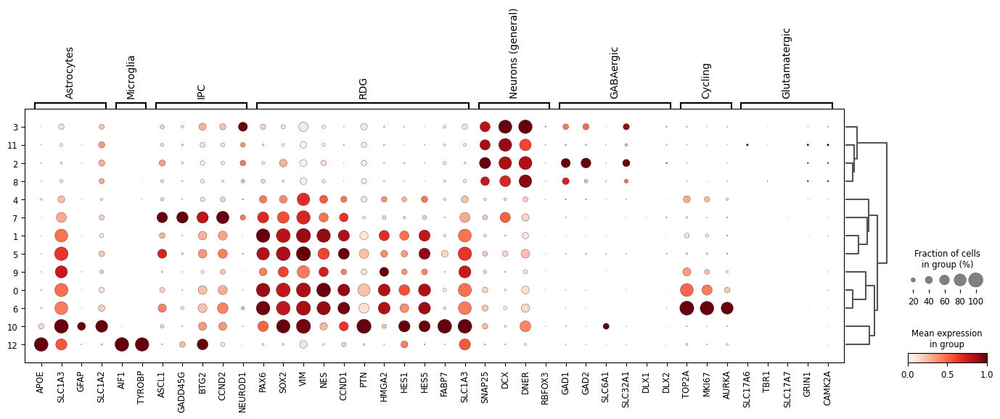

In [34]:
sc.tl.dendrogram(jessa, groupby="leiden")

    
sc.pl.dotplot(jessa, var_names=genes.prov_ann, groupby="leiden",standard_scale="var", dendrogram=True)
sc.pl.dotplot(jessa, var_names=filtered_markers, groupby="leiden",standard_scale="var", dendrogram=True)

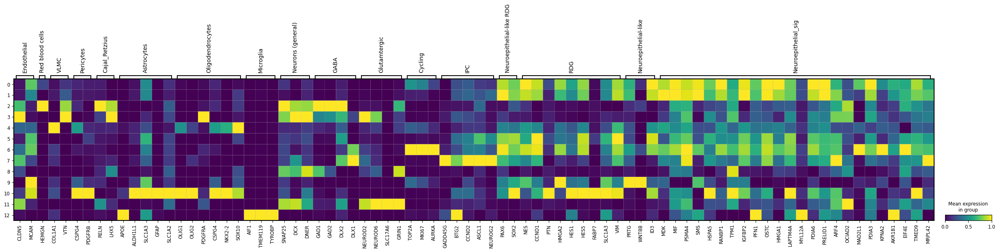

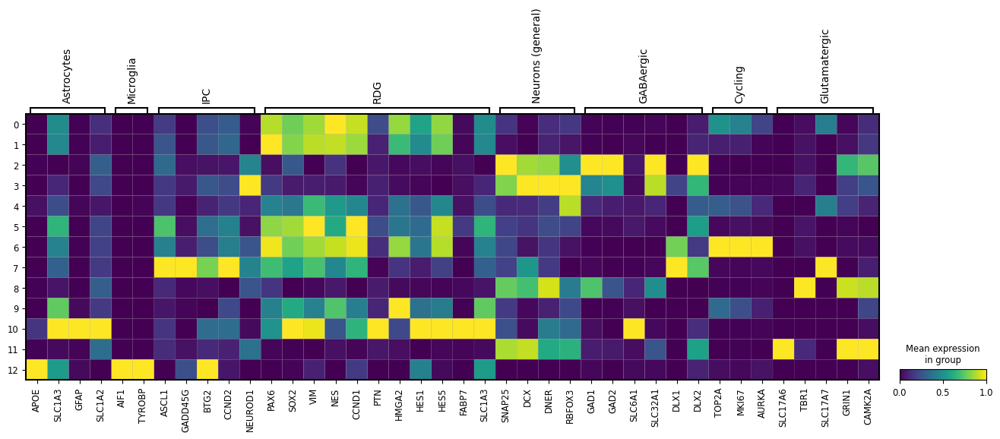

In [35]:
sc.pl.matrixplot(jessa, genes.prov_ann, groupby="leiden", dendrogram=False, standard_scale="var")
sc.pl.matrixplot(jessa, filtered_markers, groupby="leiden", dendrogram=False, standard_scale="var")

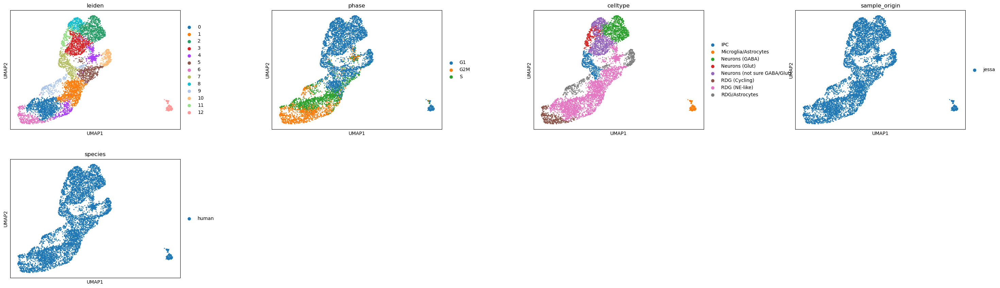

In [36]:
cluster_id = {
    "0":"RDG (NE-like)",
    "1":"RDG (NE-like)",
    "2":"Neurons (GABA)",
    "3":"Neurons (not sure GABA/Glut)",
    "4":"RDG (NE-like)",
    "5":"RDG (NE-like)",
    "6":"RDG (Cycling)",
    "7":"IPC",
    "8":"Neurons (not sure GABA/Glut)",
    "9":"RDG/Astrocytes",
    "10":"RDG/Astrocytes",
    "11":"Neurons (Glut)",
    "12":"Microglia/Astrocytes"
}

jessa.obs["celltype"] = (
    jessa.obs["leiden"]
    .map(cluster_id)
)

sc.pl.embedding(jessa, basis="umap", color=["leiden", "phase", "celltype","sample_origin", "species"], wspace=0.4)

## Integrate

In [ ]:
import anndata as ad

common_genes = defaria.var_names.intersection(jessa.var_names)

defaria_filtered = defaria[:, common_genes].copy()
jessa_filtered = jessa[:, common_genes].copy()
jessa_filtered.obs["sample_origin"] = jessa_filtered.obs["sample_origin"].astype(str)
defaria_filtered.obs_names = defaria_filtered.obs["sample_origin"] + "_" + defaria_filtered.obs_names
jessa_filtered.obs_names = jessa_filtered.obs["sample_origin"] + "_" + jessa_filtered.obs_names


combined_adata = ad.concat(
    [defaria_filtered, jessa_filtered],
    label="paper",
    keys=["defaria", "jessa"]
)

In [43]:
del combined_adata.obsm, combined_adata.layers["scale.data"]
combined_adata.X = combined_adata.layers["counts"].copy()

Maybe recalculate qc metrics??

In [44]:
combined_adata = functions.preprocess_adata(combined_adata)

In [45]:
combined_adata

AnnData object with n_obs × n_vars = 8629 × 25195
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'leiden', 'S_score', 'G2M_score', 'phase', 'celltype', 'sample_origin', 'species', 'paper'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'hvg', 'log1p'
    layers: 'counts', 'scale.data'

In [46]:
gene_counts = pd.Series(combined_adata.var_names).value_counts()
problem_genes = gene_counts[gene_counts > 1]

print(problem_genes)

Series([], Name: count, dtype: int64)


### Human samples

2026-03-06 17:01:25,303 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-03-06 17:01:27,120 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-03-06 17:01:27,156 - harmonypy - INFO - Iteration 1 of 10
2026-03-06 17:01:29,375 - harmonypy - INFO - Iteration 2 of 10
2026-03-06 17:01:31,590 - harmonypy - INFO - Iteration 3 of 10
2026-03-06 17:01:33,803 - harmonypy - INFO - Iteration 4 of 10
2026-03-06 17:01:36,027 - harmonypy - INFO - Iteration 5 of 10
2026-03-06 17:01:38,241 - harmonypy - INFO - Iteration 6 of 10
2026-03-06 17:01:40,481 - harmonypy - INFO - Iteration 7 of 10
2026-03-06 17:01:42,308 - harmonypy - INFO - Converged after 7 iterations


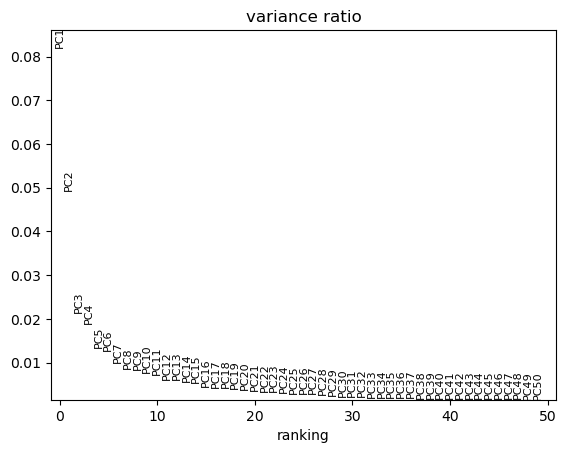

In [47]:
sc.pp.pca(combined_adata, use_highly_variable=True,  n_comps=50, layer="scale.data")
sc.pl.pca_variance_ratio(combined_adata, n_pcs=50, log=False, show=False)

sc.external.pp.harmony_integrate(combined_adata, key="sample_origin")

In [48]:
pc_parameters = parameters.pc_parameters

pc_parameters["leiden_resolution"] = [0.5, 0.8, 1, 1.2]

sc.pp.neighbors(
                combined_adata,
                n_neighbors=pc_parameters["n_neighbors"],
                n_pcs=pc_parameters["n_pcs"],
                use_rep="X_pca_harmony"
            ) #compute the neighborhood graph of cells using the specified number of neighbors and PCs, which will be used for UMAP and Leiden clustering

            # UMAP
sc.tl.umap(
            combined_adata
            )

for r in pc_parameters["leiden_resolution"]:
# Leiden through grid search
    sc.tl.leiden(
                combined_adata,
                resolution=r, 
                key_added="resolution: "+ str(r)
            )
    


In [49]:
for r in pc_parameters["leiden_resolution"]:
# Leiden through grid search
    sc.tl.leiden(
                combined_adata,
                resolution=r, 
                key_added="resolution: "+ str(r)
            )



In [50]:
combined_adata.obs.filter(['n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'S_score', 'G2M_score', 'phase', 'celltype', 'sample_origin', 'species', 'resolution: 0.5', 'resolution: 0.8', 'resolution: 1', 'resolution: 1.2'])

,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo,S_score,G2M_score,phase,celltype,sample_origin,species,resolution: 0.5,resolution: 0.8,resolution: 1,resolution: 1.2
defaria_AAACCCAGTAGACGTG-1,3104,9248.0,218.0,2.357266,2343.0,25.335207,-0.211686,-0.109580,G1,Neurons/IPC,defaria,human,3,7,10,5
defaria_AAACGAATCCGAGCTG-1,676,1095.0,119.0,10.867580,209.0,19.086758,-0.063132,0.010030,G2M,Microglia,defaria,human,4,4,4,2
defaria_AAACGAATCGGTCTGG-1,1882,3840.0,222.0,5.781250,70.0,1.822917,-0.240926,-0.190155,G1,Neurons,defaria,human,0,2,1,6
defaria_AAACGCTGTTCCGCGA-1,1206,2751.0,92.0,3.344239,833.0,30.279900,0.187162,0.068984,S,RDG,defaria,human,4,9,6,7
defaria_AAACGCTTCGTTCTCG-1,406,532.0,10.0,1.879699,77.0,14.473684,-0.053632,0.001655,G2M,Neurons,defaria,human,4,4,4,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
jessa_TTTGTCAAGTGTCCCG-1,597,785.0,10.0,1.273885,156.0,19.872611,0.257344,0.151595,S,RDG (NE-like),jessa,human,4,4,4,2
jessa_TTTGTCAGTAAAGGAG-1,4276,11668.0,191.0,1.636956,2048.0,17.552280,-0.287716,-0.216892,G1,Neurons (GABA),jessa,human,0,5,5,10
jessa_TTTGTCAGTACAGCAG-1,5088,13155.0,224.0,1.702775,1229.0,9.342455,-0.269624,-0.194281,G1,RDG/Astrocytes,jessa,human,6,11,12,13
jessa_TTTGTCATCAATCTCT-1,531,605.0,8.0,1.322314,62.0,10.247934,-0.027547,0.002971,G2M,RDG (NE-like),jessa,human,4,4,4,2


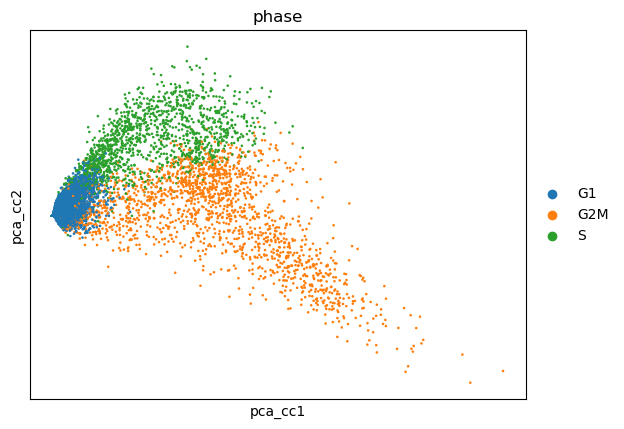

In [51]:
s_genes = [x for x in genes.s_genes if x in combined_adata.var_names]

g2m_genes = [x for x in genes.g2m_genes if x in combined_adata.var_names]

cell_cycle_genes = [*s_genes, *g2m_genes]

sc.tl.score_genes_cell_cycle(combined_adata, s_genes=s_genes, g2m_genes=g2m_genes)

datacc_genes = combined_adata[:, cell_cycle_genes].copy()
sc.tl.pca(datacc_genes, layer="scale.data", key_added="pca_cc")
sc.pl.embedding(datacc_genes, color="phase", basis="pca_cc")



In [52]:
import numpy as np
np.std(combined_adata.layers["scale.data"], axis=0).mean()

np.float64(0.994901663590658)

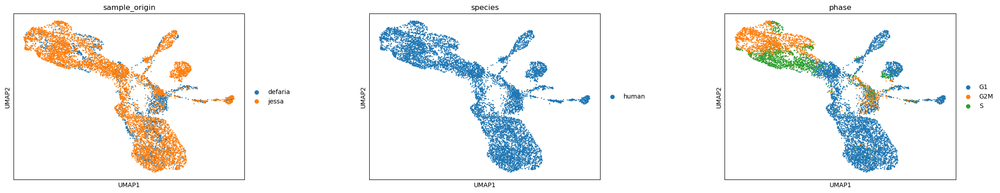

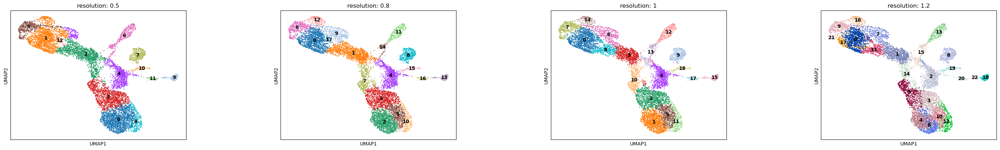

In [53]:
sc.pl.embedding(combined_adata, basis="umap", color=["sample_origin", "species", "phase"], wspace=0.4)
sc.pl.embedding(combined_adata, basis="umap", color=['resolution: 0.5', 'resolution: 0.8', 'resolution: 1', 'resolution: 1.2'], wspace=0.4,legend_loc='on data')

In [54]:
proportion_lst = dict()


for r in ['resolution: 0.5', 'resolution: 0.8', 'resolution: 1', 'resolution: 1.2']:
    prop_df = pd.crosstab(
    combined_adata.obs[r],
    combined_adata.obs["sample_origin"],
    normalize="index"
) * 100
    proportion_lst[r] = prop_df
    print(prop_df)

#liking 0.8


sample_origin       defaria      jessa
resolution: 0.5                       
0                 23.047619  76.952381
1                  9.491525  90.508475
2                 15.578635  84.421365
3                 28.417564  71.582436
4                 59.231590  40.768410
5                 13.663366  86.336634
6                 18.544601  81.455399
7                  1.243781  98.756219
8                  6.730769  93.269231
9                 29.714286  70.285714
10                78.151261  21.848739
11                52.747253  47.252747
12               100.000000   0.000000
sample_origin       defaria      jessa
resolution: 0.8                       
0                  9.756098  90.243902
1                 17.283951  82.716049
2                 23.384895  76.615105
3                 31.288981  68.711019
4                 60.315375  39.684625
5                 22.489960  77.510040
6                 12.168142  87.831858
7                 15.023474  84.976526
8                  1.2437

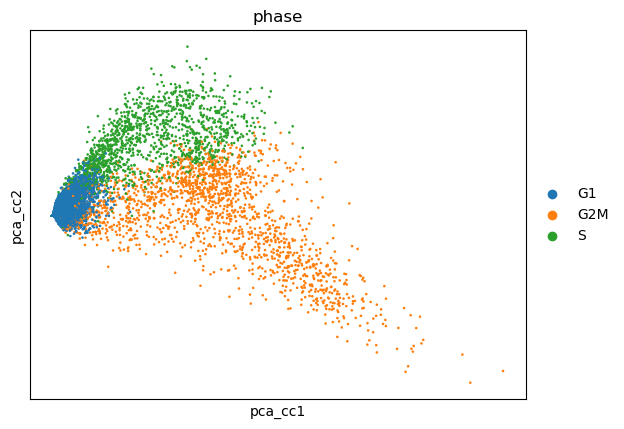

In [55]:
s_genes = [x for x in genes.s_genes if x in combined_adata.var_names]

g2m_genes = [x for x in genes.g2m_genes if x in combined_adata.var_names]

cell_cycle_genes = [*s_genes, *g2m_genes]


#Should be performed on normalized and log-transformed data
sc.tl.score_genes_cell_cycle(combined_adata, s_genes=s_genes, g2m_genes=g2m_genes)

datacc_genes = combined_adata[:, cell_cycle_genes].copy() #PCA will be computed on whola dataset because scanpy uses a snapshot instead of keeping raw, scaled data, and variable gene info in separate slots
sc.tl.pca(datacc_genes, layer="scale.data", key_added="pca_cc")
sc.pl.embedding(datacc_genes, color="phase", basis="pca_cc")



In [56]:
#We should try different methods

sc.tl.rank_genes_groups(combined_adata, groupby="resolution: 0.8",  method="logreg", use_raw=True)

In [57]:
human_tumor_generank = sc.get.rank_genes_groups_df(combined_adata, group=None)

In [58]:
human_tumor_generank

,group,names,scores
0,0,HIST1H4C,0.310234
1,0,RRM2,0.300485
2,0,KIAA0101,0.275946
3,0,HMGB2,0.233604
4,0,TK1,0.211338
...,...,...,...
453505,17,SOX4,-0.053728
453506,17,RPL13A,-0.054068
453507,17,HES6,-0.055391
453508,17,C1orf61,-0.063903


In [59]:
human_tumor_generank

,group,names,scores
0,0,HIST1H4C,0.310234
1,0,RRM2,0.300485
2,0,KIAA0101,0.275946
3,0,HMGB2,0.233604
4,0,TK1,0.211338
...,...,...,...
453505,17,SOX4,-0.053728
453506,17,RPL13A,-0.054068
453507,17,HES6,-0.055391
453508,17,C1orf61,-0.063903


In [60]:
top_bottom_human = pd.concat([
    human_tumor_generank.sort_values('scores', ascending=False).groupby('group', group_keys=False).head(20),
    human_tumor_generank.sort_values('scores', ascending=True).groupby('group', group_keys=False).head(20)
])

top_bottom_human

,group,names,scores
251950,10,LAMP5,0.377421
0,0,HIST1H4C,0.310234
1,0,RRM2,0.300485
75585,3,RND3,0.300352
125975,5,NEFM,0.290771
...,...,...,...
352714,13,ERBB4,-0.034359
352713,13,PTMS,-0.034148
352712,13,NCL,-0.033254
352711,13,LINC00461,-0.032844


In [61]:
top_bottom_human.to_csv("/home/sofia/Projects/etmr/defaria/scRNA/tables/integrated/top_bottom_per_group_human.csv", index=False)

In [62]:
top_bottom_human.groupby('group').size()

group
0     40
1     40
2     40
3     40
4     40
5     40
6     40
7     40
8     40
9     40
10    40
11    40
12    40
13    40
14    40
15    40
16    40
17    40
dtype: int64

In [63]:
genes.prov_ann = {
    "Endothelial": ["CLDN5", "MCAM"],
    "Red blood cells": ["HEMGN"],
    "VLMC": ["COL1A1", "VTN"],
    "Pericytes": ["CSPG4", "PDGFRB"],
    "Cajal_Retzius": ["RELN", "LHX5"],
    "Astrocytes": ["APOE", "ALDH1L1", "GFAP", "SLC1A2"],
    "Oligodendrocytes": ["OLIG1", "OLIG2", "PDGFRA", "CSPG4", "NKX2-2", "SOX10"],
    "Microglia": ["AIF1", "TMEM119", "TYROBP"],
    "Neurons (general)": ["SNAP25", "DCX", "DNER"],
    "GABA": ["GAD1", "GAD2", "DLX2", "DLX1"],
    "Glutamtergic": ["NEUROD2", "NEUROD6", "SLC17A6", "GRIN1"],
    "Cycling": ["TOP2A", "MKI67", "AURKA"],
    "IPC": ["GADD45G", "BTG2", "CCND2", # general
         "ASCL1",                    # inhibitorias
         "NEUROG2"]  ,
    "RDG": ["NES", "CCND1", "PTN", "HMGA2", "HES1", "HES5", "FABP7", "SLC1A3", "VIM"],
    "Neuroepithelial-like": ["PRTG", "ID3", "PAX6", "SOX2"],
    "Neuroepithelial_sig" : [
"MDK",
"MIF",
# "AC090498.1",
"PSMA4",
"SMS",
"HSPA5",
"RANBP1",
"TPM1",
"IGFBP2",
"PFN1",
"OSTC",
"HMGA1",
"LAPTM4A",
"MYL12A",
"PDIA6",
"PRELID1",
"ARF4",
"OCIAD2",
"MAD2L1",
"PDIA3",
"KPNA2",
"AKR1B1",
"EIF4E",
"TMED9",
"MRPL42"
]
}


categories: 0, 1, 2, etc.
var_group_labels: Endothelial, Red blood cells, VLMC, etc.


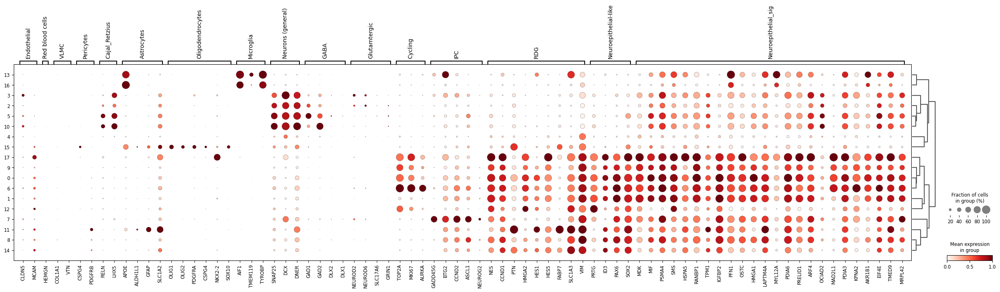

In [64]:
sc.tl.dendrogram(combined_adata, groupby="resolution: 0.8")

    
sc.pl.dotplot(combined_adata, var_names=genes.prov_ann, groupby="resolution: 0.8",standard_scale="var", dendrogram=True)

In [65]:
combined_adata.uns['rank_genes_groups']['names']

rec.array([('HIST1H4C', 'DAB1', 'STMN2', 'RND3', 'MALAT1', 'NEFM', 'HMGB2', 'JAG1', 'C1orf61', 'PTTG1', 'LAMP5', 'PTN', 'ATAD2', 'CD74', 'C1orf61', 'CST3', 'FTL', 'HIST1H4C'),
           ('RRM2', 'MDK', 'NRXN1', 'ROBO3', 'TUBA1A', 'TAC1', 'PTTG1', 'HES6', 'FGFBP3', 'HMGB2', 'CACNA2D3', 'FABP7', 'DIAPH3', 'HLA-DRA', 'PTN', 'PTN', 'APOE', 'HMGB2'),
           ('KIAA0101', 'RP11-32K4.1', 'CELF4', 'DCC', 'RPS14', 'CACNA2D3', 'TOP2A', 'DLL1', 'VIM', 'CDC20', 'PAX2', 'PMP2', 'C2orf48', 'HLA-DRB1', 'SCN1A', 'B2M', 'C1QB', 'DHFR'),
           ...,
           ('TTC3', 'HMGB2', 'CACNA2D3', 'HES4', 'CKS2', 'ID2', 'SOX4', 'PTN', 'STMN1', 'FOS', 'ZNF536', 'STMN1', 'H3F3B', 'MARCKSL1', 'KPNA2', 'PABPC1', 'POLR2J', 'HES6'),
           ('TMSB10', 'C1orf61', 'SOX2', 'LSAMP', 'APOE', 'LINC00461', 'FTL', 'TTYH1', 'MDK', 'THSD4', 'PAX3', 'MT-CO3', 'NRXN3', 'TUBB2B', 'STMN2', 'SOX4', 'SNRPD2', 'C1orf61'),
           ('MALAT1', 'TOP2A', 'VIM', 'VIM', 'C1orf61', 'VIM', 'MEG3', 'HMGB2', 'CRABP1', 'MT-ATP6', '

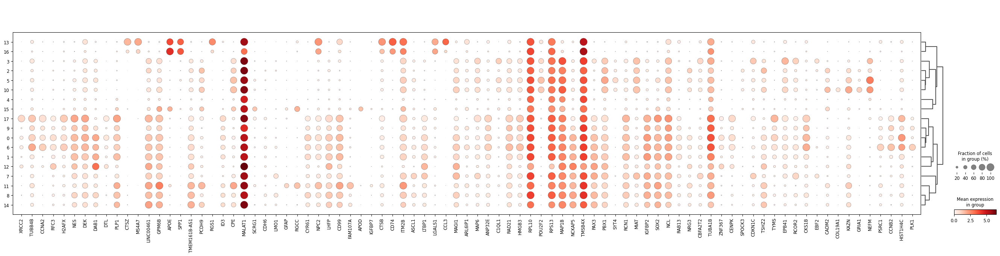

In [66]:
top5 = top_bottom_human.loc[top_bottom_human["scores"] > 0].sort_values('scores', ascending=True).groupby('group', group_keys=False).head(5)

sc.pl.dotplot(combined_adata, var_names=top5["names"].unique(), groupby="resolution: 0.8",standard_scale=None, dendrogram=True)

categories: 0, 1, 2, etc.
var_group_labels: Endothelial, Red blood cells, VLMC, etc.


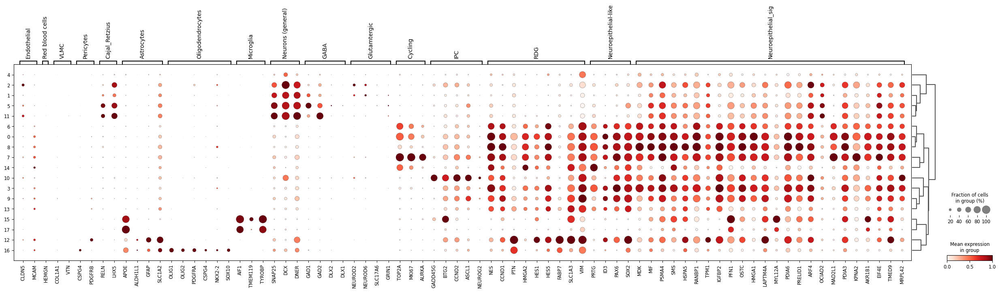

categories: 0, 1, 2, etc.
var_group_labels: Endothelial, Red blood cells, VLMC, etc.


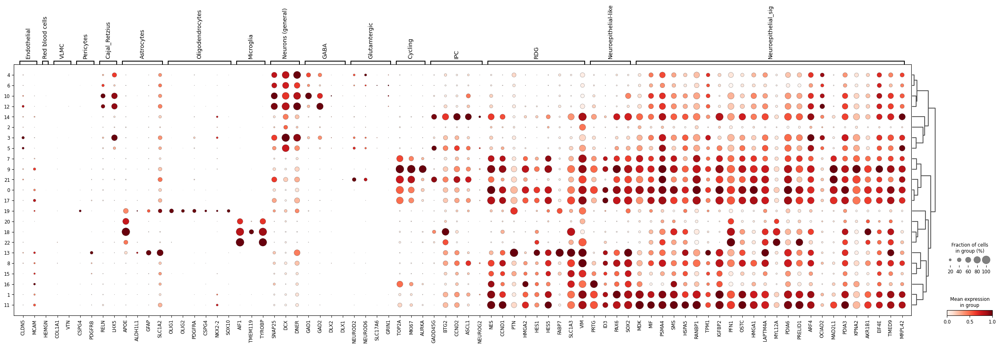

In [67]:


sc.tl.dendrogram(combined_adata, groupby="resolution: 1")
sc.pl.dotplot(combined_adata, var_names=genes.prov_ann, groupby="resolution: 1",standard_scale="var", dendrogram=True)

sc.tl.dendrogram(combined_adata, groupby="resolution: 1.2")
sc.pl.dotplot(combined_adata, var_names=genes.prov_ann, groupby="resolution: 1.2",standard_scale="var", dendrogram=True)

### Mouse

In [71]:
humanized_data = sc.read_h5ad("/media/sofia/TOSHIBA EXT/data/mouse/so_12_SP_KO_WT_just_joined_humanized.h5ad")
humanized_data.X = humanized_data.layers["counts"].copy()

common_genes = combined_adata.var_names.intersection(humanized_data.var_names)

combined_adata_filtered = combined_adata[:, common_genes].copy()
humanized_data_filtered = humanized_data[:, common_genes].copy()

combined_adata_filtered.obs["species"] = combined_adata_filtered.obs["species"].astype(str)
humanized_data_filtered.obs["species"] = "mouse"

combined_adata_filtered.obs_names = combined_adata_filtered.obs["species"] + "_" + combined_adata_filtered.obs_names
humanized_data_filtered.obs_names = humanized_data_filtered.obs["species"] + "_" + humanized_data_filtered.obs_names


In [72]:
gene_counts = pd.Series(combined_adata.var_names).value_counts()
problem_genes = gene_counts[gene_counts > 1]

print(problem_genes)

Series([], Name: count, dtype: int64)


In [73]:

combined_adata_mouse = ad.concat(
    [combined_adata_filtered, humanized_data_filtered],
    label="species",
    keys=["human", "mouse"]
)

In [74]:
combined_adata_mouse.write_h5ad("/home/sofia/Projects/etmr/defaria/scRNA/data/processed/merged_bothhuman_mouse.h5ad")

In [75]:
combined_adata_mouse = sc.read_h5ad("/home/sofia/Projects/etmr/defaria/scRNA/data/processed/merged_bothhuman_mouse.h5ad")

In [76]:
combined_adata_mouse = functions.preprocess_adata(combined_adata_mouse)

In [77]:
sc.pp.pca(combined_adata_mouse)

In [78]:
sc.external.pp.harmony_integrate(combined_adata_mouse, key="sample_origin")

2026-03-06 17:07:23,092 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-03-06 17:07:36,031 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-03-06 17:07:36,350 - harmonypy - INFO - Iteration 1 of 10
2026-03-06 17:08:00,104 - harmonypy - INFO - Iteration 2 of 10
2026-03-06 17:08:23,965 - harmonypy - INFO - Iteration 3 of 10
2026-03-06 17:08:47,802 - harmonypy - INFO - Iteration 4 of 10
2026-03-06 17:09:11,863 - harmonypy - INFO - Iteration 5 of 10
2026-03-06 17:09:35,979 - harmonypy - INFO - Iteration 6 of 10
2026-03-06 17:10:00,034 - harmonypy - INFO - Iteration 7 of 10
2026-03-06 17:10:22,095 - harmonypy - INFO - Converged after 7 iterations


Fix the next part later

In [79]:
pc_parameters = parameters.pc_parameters

sc.pp.neighbors(
                combined_adata_mouse,
                n_neighbors=pc_parameters["n_neighbors"],
                n_pcs=pc_parameters["n_pcs"],
                use_rep="X_pca_harmony"
            ) #compute the neighborhood graph of cells using the specified number of neighbors and PCs, which will be used for UMAP and Leiden clustering

            # UMAP
sc.tl.umap(
                combined_adata_mouse
            )

            # Leiden
sc.tl.leiden(
                combined_adata_mouse,
                resolution=pc_parameters["leiden_resolution"]
            )

TypeError: must be real number, not list

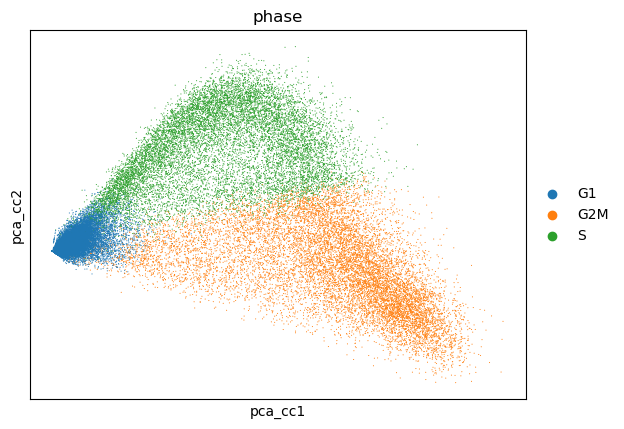

In [ ]:
s_genes = [x for x in genes.s_genes if x in combined_adata_mouse.var_names]

g2m_genes = [x for x in genes.g2m_genes if x in combined_adata_mouse.var_names]

cell_cycle_genes = [*s_genes, *g2m_genes]

sc.tl.score_genes_cell_cycle(combined_adata_mouse, s_genes=s_genes, g2m_genes=g2m_genes)

datacc_genes = combined_adata_mouse[:, cell_cycle_genes].copy()
sc.tl.pca(datacc_genes, layer="scale.data", key_added="pca_cc")
sc.pl.embedding(datacc_genes, color="phase", basis="pca_cc")

sc.tl.rank_genes_groups(combined_adata_mouse, groupby="leiden",  method="wilcoxon", use_raw=False)

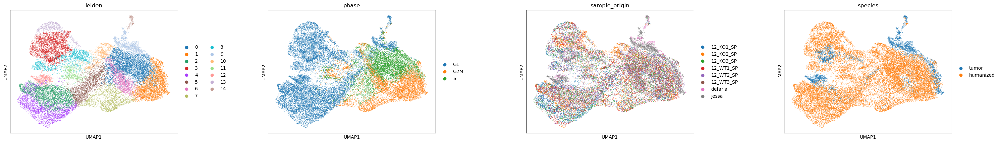

In [ ]:
sc.pl.embedding(combined_adata_mouse, basis="umap", color=["leiden", "phase", "sample_origin", "species"], wspace=0.4)

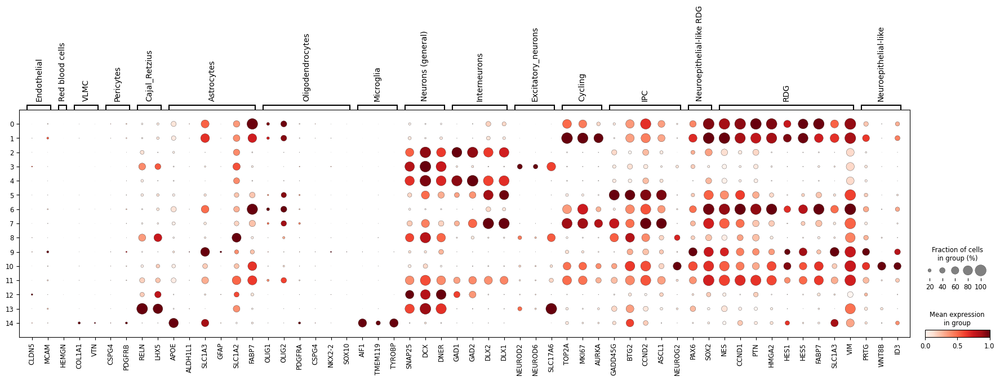

In [ ]:
sc.tl.dendrogram(combined_adata_mouse, groupby="leiden")

    
sc.pl.dotplot(combined_adata_mouse, var_names=genes.prov_ann, groupby="leiden",standard_scale="var", dendrogram=False)

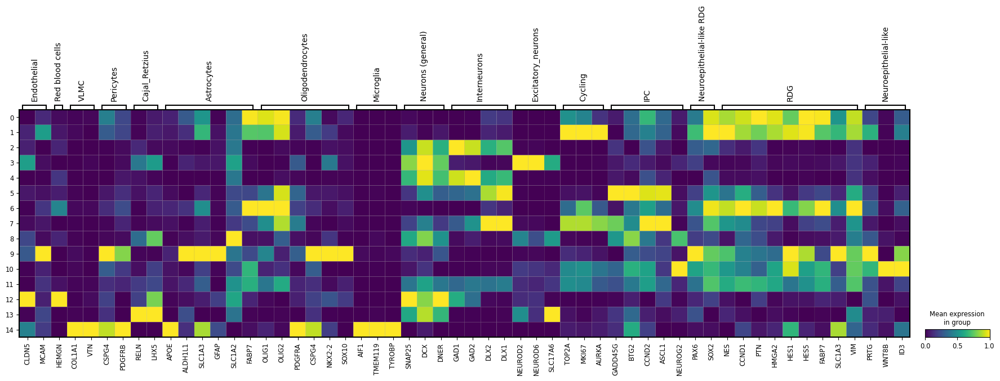

In [ ]:
sc.pl.matrixplot(combined_adata_mouse, genes.prov_ann, groupby="leiden", dendrogram=False, standard_scale="var")


In [ ]:
prop_df = pd.crosstab(
    combined_adata_mouse.obs["leiden"],
    combined_adata_mouse.obs["species"],
    normalize="index"
) * 100

prop_df

species,human,mouse
leiden,,
0,0.905608,99.094392
1,28.092524,71.907476
2,7.500424,92.499576
3,25.869411,74.130589
4,0.926656,99.073344
5,7.051464,92.948536
6,4.936624,95.063376
7,2.886957,97.113043
8,11.048755,88.951245


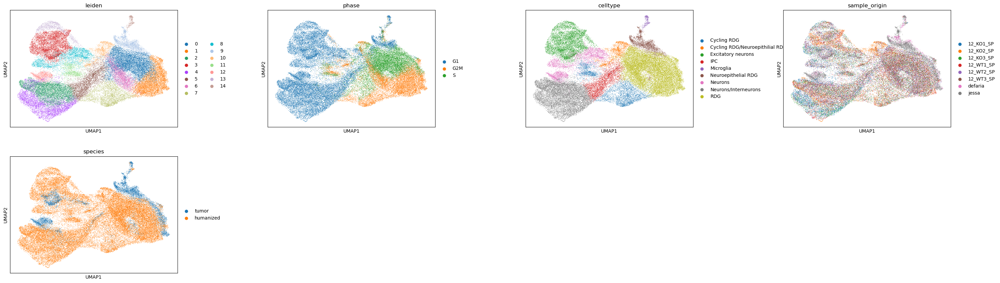

In [ ]:
cluster_id = {
    "0":"RDG",
    "1":"RDG",
    "2":"Neurons/Interneurons",
    "3":"Excitatory neurons",
    "4":"Neurons/Interneurons",
    "5":"IPC",
    "6":"RDG",
    "7":"Cycling RDG",
    "8":"Neurons",
    "9":"Neuroepithelial RDG",
    "10":"Cycling RDG/Neuroepithilial RDG",
    "11":"Cycling RDG",
    "12":"Neurons",
    "13":"Excitatory neurons",
    "14":"Microglia"

}

cluster_id = {
    "0":"RDG",
    "1":"RDG",
    "2":"Neurons/Interneurons",
    "3":"Excitatory neurons",
    "4":"Neurons/Interneurons",
    "5":"IPC",
    "6":"RDG",
    "7":"Cycling RDG",
    "8":"Neurons",
    "9":"Neuroepithelial RDG",
    "10":"Cycling RDG/Neuroepithilial RDG",
    "11":"Cycling RDG",
    "12":"Neurons",
    "13":"Excitatory neurons",
    "14":"Microglia"

}

combined_adata_mouse.obs["celltype"] = (
    combined_adata_mouse.obs["leiden"]
    .map(cluster_id)
)

sc.pl.embedding(combined_adata_mouse, basis="umap", color=["leiden", "phase", "celltype","sample_origin", "species"], wspace=0.4)



In [ ]:
combined_adata_mouse.write_h5ad("/home/sofia/Projects/etmr/defaria/scRNA/data/processed/merged_bothhuman_mouse_int.h5ad")